# 21 — PPO: fixed snapshots, multiple data passes
ActorCritic는 B=1 즉시 업데이트, A2C는 T×N 단일 업데이트, PPO는 같은 Rollout을 여러 Epoch의 Minibatch로 학습한다. 별도 PPOBuffer 없이 B.Rollout을 재사용한다. Gymnasium >=1.1 SAME_STEP을 사용한다.

[GAE 논문](https://arxiv.org/abs/1506.02438), [PPO 논문](https://arxiv.org/abs/1707.06347). FAST는 실행 호환성 검사이며 FULL은 실제 CartPole 학습이다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
from gymnasium.vector import AsyncVectorEnv, AutoresetMode
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from modular_rl import Model, representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.environment import validate_vector_env, final_observations
from notebooks.gymnasium.tutorial_utils import evaluate, history, record


FAST = os.environ.get('MODULARRL_FAST', '0') == '1'
SEED, GAMMA, LAM = 7, .99, .95
N_ENVS, HORIZON = 4, 16 if FAST else 128
STEP_BUDGET = 256 if FAST else 81920  # individual environment transitions
EPOCHS, MINIBATCH_SIZE = 4, 64
LEARNING_RATE = .0003
assert STEP_BUDGET % (N_ENVS*HORIZON) == 0
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print(dict(mode='FAST' if FAST else 'FULL',seed=SEED,gamma=GAMMA,lam=LAM,
           n_envs=N_ENVS,horizon=HORIZON,environment_steps=STEP_BUDGET,
           epochs=EPOCHS,minibatch_size=MINIBATCH_SIZE,learning_rate=LEARNING_RATE))

{'mode': 'FULL', 'seed': 7, 'gamma': 0.99, 'lam': 0.95, 'n_envs': 4, 'horizon': 128, 'environment_steps': 81920, 'epochs': 4, 'minibatch_size': 64, 'learning_rate': 0.0003}


## 컴포넌트 구성
수집 정책을 Rollout 동안 고정한다. 첫 learn 직전에 value/log_prob을 비교하며, Epoch 안에서는 현재 정책의 변화가 정상이다. 이 검사는 데이터의 소유권이나 모든 Parameter 변경을 인증하지 않는다. 동일 Rollout의 재전달도 새 데이터라는 보장은 없다.

In [2]:
model = Model(R.MLP(4,hidden_dims=(64,),activation=nn.Tanh),
              E.ActorCritic(E.CategoricalPolicy(64,2),E.StateValue(64)),S.Categorical())
model.eval()  # deterministic forwards, still differentiable
optimizer = torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
buffer = B.Rollout(HORIZON,N_ENVS)
target_generator = T.GAE(gamma=GAMMA,lam=LAM)
update_rule = U.PPO(clip_epsilon=.2,value_coef=.5,entropy_coef=.01)
learner = L.PPO(model,optimizer,target_generator,update_rule,epochs=EPOCHS,
                minibatch_size=MINIBATCH_SIZE,seed=SEED,normalize_advantage=True)
with gym.make('CartPole-v1') as eval_env:
    before = evaluate(eval_env,lambda obs:model.act(obs,deterministic=True).action.item(),
                      episodes=3 if FAST else 20,seed=SEED+1000)
print('before mean return',float(np.mean(before['rewards'])))

before mean return 9.2


## Clipped objective와 경계
$\rho=\exp(\log\pi_\theta-\log\pi_{old})$, $L_\pi=-E[\min(\rho A,\operatorname{clip}(\rho,1-\epsilon,1+\epsilon)A)]$.
Negative Advantage에서도 min을 그대로 사용한다. Critic은 $\frac12E[(V-R)^2]$, 전체 Loss는 $L_\pi+c_vL_v-\beta H$다. Ratio=1에서 첫 Actor Gradient는 AC와 같지만 Loss 숫자는 `-A`와 `-log_prob*A`로 다르다.

GAE는 실제 Final Observation의 V로 Bootstrap한다. terminated는 Bootstrap을 없애고, terminated 또는 truncated는 Trace를 끊는다. Reset 관측을 이전 전이의 next_observation으로 저장하지 않는다. old_value/log_prob, GAE/Return은 learn 시작 시 고정한다. 전체 T*N Advantage를 population variance로 한 번 정규화한다. 표본 1개/상수 Advantage는 0이 되므로 Actor surrogate Gradient가 사라진다. 필요하면 normalize_advantage=False를 사용한다.

In [3]:
log = history()
episode_steps, updates, losses = [], [], []
policy_losses, value_losses, entropies, approx_kls, clip_fractions = [], [], [], [], []
totals, lengths = np.zeros(N_ENVS), np.zeros(N_ENVS,dtype=np.int64)
environment_steps, optimizer_steps = 0, 0
env = AsyncVectorEnv(
    [lambda:gym.make('CartPole-v1',max_episode_steps=60 if FAST else 500) for _ in range(N_ENVS)],
    context='spawn',copy=True,autoreset_mode=AutoresetMode.SAME_STEP)
try:
    validate_vector_env(env)
    observation,_ = env.reset(seed=[SEED+i for i in range(N_ENVS)])
    for rollout_index in range(STEP_BUDGET//(N_ENVS*HORIZON)):
        for _ in range(HORIZON):
            with torch.no_grad():
                estimate = model(observation)
                selected = model.action_selector.select(estimate)
            returned,reward,terminated,truncated,info = env.step(selected.action.cpu().numpy())
            actual_next = final_observations(returned,terminated,truncated,info)
            buffer.add(observation,selected.action,reward,actual_next,terminated,truncated,
                       value=estimate.values.v,log_prob=selected.log_prob)
            environment_steps += N_ENVS
            totals += reward; lengths += 1
            for index in np.flatnonzero(terminated | truncated):
                record(log,totals[index],lengths[index],terminated[index],truncated[index])
                episode_steps.append(environment_steps)
                totals[index]=0.;lengths[index]=0
            observation=returned  # reset observation only for the next action
        rollout=buffer.get()
        result=learner.learn(rollout)  # GAE once; old snapshots fixed throughout all epochs
        optimizer_steps += result.optimizer_steps
        losses.append(result.total_loss.item());policy_losses.append(result.policy_loss.item())
        value_losses.append(result.value_loss.item());entropies.append(result.entropy.item())
        approx_kls.append(result.approx_kl.item());clip_fractions.append(result.clip_fraction.item())
        updates.append(environment_steps)
        buffer.clear()  # collect a fresh rollout with the updated policy
        if (rollout_index+1) % (1 if FAST else 20)==0:
            print('rollout',rollout_index+1,'steps',environment_steps,'optimizer steps',optimizer_steps,
                  'episodes',len(log['rewards']),'recent return',round(float(np.mean(log['rewards'][-20:])),2),
                  'KL',round(approx_kls[-1],6),'clip fraction',round(clip_fractions[-1],4))
except BaseException:
    env.close(terminate=True)
    raise
finally:
    env.close()
print('unfinished episode lengths',lengths.tolist())

rollout 20 steps 10240 optimizer steps 640 episodes 287 recent return 45.65 KL 0.000298 clip fraction 0.0


rollout 40 steps 20480 optimizer steps 1280 episodes 489 recent return 49.6 KL 0.009163 clip fraction 0.1094


rollout 60 steps 30720 optimizer steps 1920 episodes 674 recent return 46.05 KL 0.00413 clip fraction 0.0249


rollout 80 steps 40960 optimizer steps 2560 episodes 807 recent return 84.0 KL 6.7e-05 clip fraction 0.0


rollout 100 steps 51200 optimizer steps 3200 episodes 925 recent return 81.7 KL 0.000323 clip fraction 0.0


rollout 120 steps 61440 optimizer steps 3840 episodes 1034 recent return 115.35 KL 2.1e-05 clip fraction 0.0


rollout 140 steps 71680 optimizer steps 4480 episodes 1123 recent return 150.55 KL 0.005712 clip fraction 0.0679


rollout 160 steps 81920 optimizer steps 5120 episodes 1218 recent return 116.55 KL 0.008145 clip fraction 0.1274
unfinished episode lengths [129, 19, 75, 24]


In [4]:
with gym.make('CartPole-v1') as eval_env:
    after=evaluate(eval_env,lambda obs:model.act(obs,deterministic=True).action.item(),
                   episodes=3 if FAST else 20,seed=SEED+1000)
summary=dict(before=float(np.mean(before['rewards'])),after=float(np.mean(after['rewards'])),
             episodes=len(log['rewards']),environment_steps=environment_steps,
             vector_steps=environment_steps//N_ENVS,rollouts=len(updates),optimizer_steps=optimizer_steps,
             data_passes=EPOCHS,sample_uses=environment_steps*EPOCHS,n_envs=N_ENVS,horizon=HORIZON,
             minibatch_size=MINIBATCH_SIZE,gamma=GAMMA,lam=LAM,learning_rate=LEARNING_RATE,seed=SEED)
print('RESULT',json.dumps(summary,sort_keys=True))
# Checkpoint boundary: save these with model/optimizer and separate action/environment RNG state.
shuffle_state=learner.shuffle_rng.get_state().clone()
print('shuffle RNG state bytes',shuffle_state.numel())

RESULT {"after": 415.25, "before": 9.2, "data_passes": 4, "environment_steps": 81920, "episodes": 1218, "gamma": 0.99, "horizon": 128, "lam": 0.95, "learning_rate": 0.0003, "minibatch_size": 64, "n_envs": 4, "optimizer_steps": 5120, "rollouts": 160, "sample_uses": 327680, "seed": 7, "vector_steps": 20480}
shuffle RNG state bytes 5056


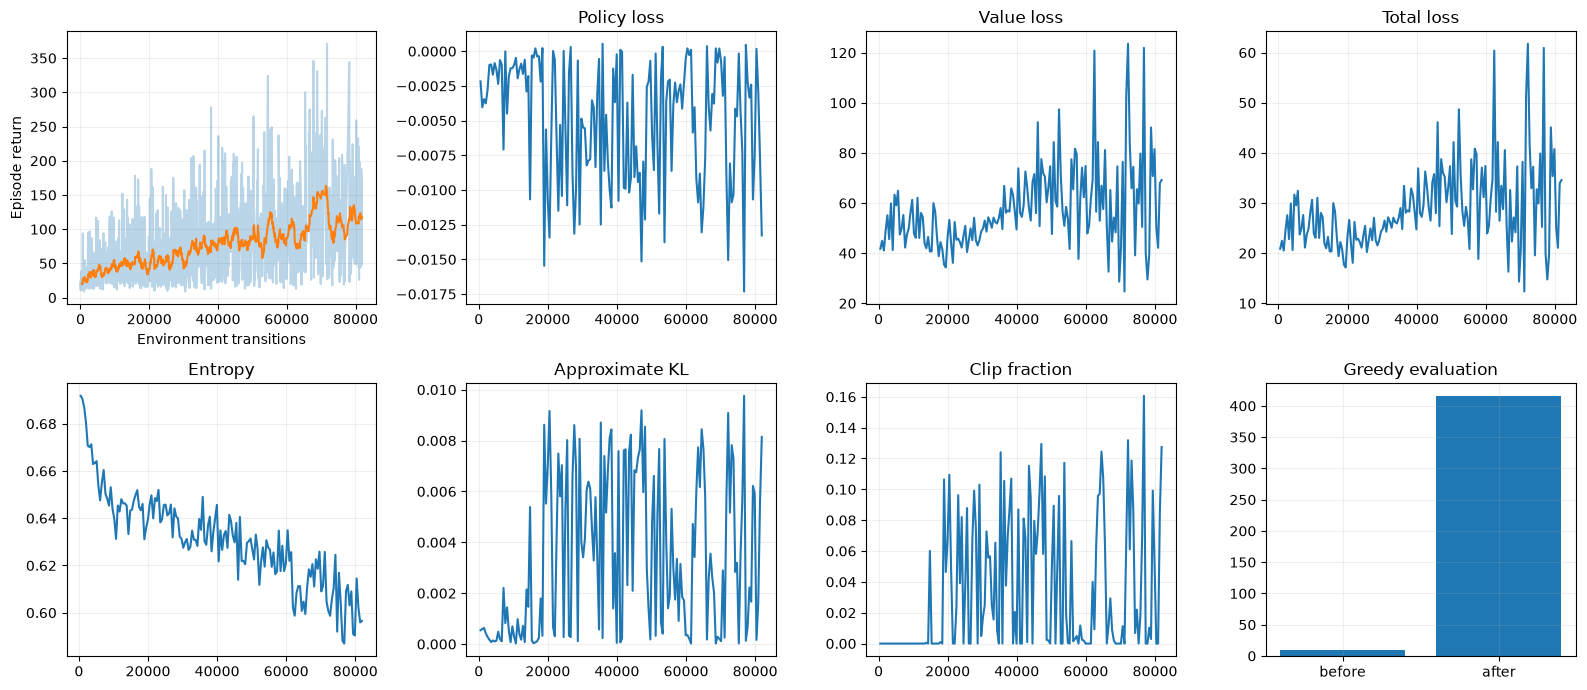

In [5]:
fig,axes=plt.subplots(2,4,figsize=(16,7))
rewards=np.asarray(log['rewards']);window=min(20,len(rewards))
axes[0,0].plot(episode_steps,rewards,alpha=.3)
axes[0,0].plot(episode_steps[window-1:],np.convolve(rewards,np.ones(window)/window,mode='valid'))
axes[0,0].set(xlabel='Environment transitions',ylabel='Episode return')
axes[0,1].plot(updates,policy_losses);axes[0,1].set_title('Policy loss')
axes[0,2].plot(updates,value_losses);axes[0,2].set_title('Value loss')
axes[0,3].plot(updates,losses);axes[0,3].set_title('Total loss')
axes[1,0].plot(updates,entropies);axes[1,0].set_title('Entropy')
axes[1,1].plot(updates,approx_kls);axes[1,1].set_title('Approximate KL')
axes[1,2].plot(updates,clip_fractions);axes[1,2].set_title('Clip fraction')
axes[1,3].bar(['before','after'],[summary['before'],summary['after']]);axes[1,3].set_title('Greedy evaluation')
for ax in axes.flat:ax.grid(alpha=.2)
fig.tight_layout();plt.show()

## 지표·재현성·한계
각 지표는 각 Minibatch 업데이트 직전 값의 표본 수 가중 평균이다. 작은 마지막 Minibatch도 포함한다. Approximate KL은 mean(ratio-1-log_ratio), Clip Fraction은 mean(abs(ratio-1)>epsilon)이다. 실제 전체 정책 KL이나 clipping으로 Gradient가 0인 표본 비율과는 다르다.

PPO shuffle_rng는 Torch 행동 RNG와 독립적이다. Checkpoint는 Model/Optimizer, shuffle_rng.get_state() 및 별도 환경/행동 RNG를 함께 저장한다. shuffle_rng.set_state()로 복원한다. 이 예제에는 Value Clipping, KL 조기 종료, Gradient Clipping, 연속 행동, Recurrent Policy를 넣지 않았다. 성능 500은 pytest 합격 조건이 아니다. A2C와 비교할 때 환경 전이 수뿐 아니라 Optimizer Step과 표본 재사용 횟수도 비교해야 한다.

## FULL 실행 기록과 비교 기준
이하 실험 결과는 FAST 셀 출력과 구분한 별도 FULL 기록이다. Seed 7/11/19/23/42에서 실제 Async CartPole을 학습했고, 각 정책을 별도 환경 20 Episode에서 Greedy 평가한다. 학습 시드가 같아도 A2C/PPO의 정책이 달라 경험 궤적은 같지 않다. 두 학습기는 같은 Tanh MLP(64)와 환경 전이 예산을 사용하지만 Horizon, 학습률, Minibatch와 표본 재사용 횟수는 다르므로 알고리즘의 보편적 우위로 해석하지 않는다.

### CartPole FULL 실행 기록 — 같은 81,920 환경 전이 예산

CPU float32, Torch thread=1, Tanh MLP(64), Categorical+V, Adam, gamma=.99,
value_coef=.5, entropy_coef=.01을 사용했다. Worker Seed는 seed+i이고 각 별도 Greedy 평가는
20 Episode, seed=학습 seed+1000+i다. 같은 Seed에서도 두 알고리즘은 같은 경험을 뜻하지 않는다.

|Seed|학습 전|PPO 평가 후|A2C 평가 후|PPO 완료 Episode|A2C 완료 Episode|
|---|---:|---:|---:|---:|---:|
|7|9.20|415.25|466.80|1218|1240|
|11|10.60|483.70|282.50|1152|938|
|19|9.35|427.65|409.75|1162|1012|
|23|9.20|147.50|400.05|1285|1035|
|42|9.15|197.50|176.00|1087|1176|

5개 Seed 평균±population 표준편차(ddof=0)는 PPO **334.32±135.05**, A2C **347.02±104.41**이다.
각 Seed 내 20 Episode 평균을 다시 요약한 통계이며 100 Episode를 독립 학습 표본처럼 합치지 않는다.

|항목|PPO|A2C|
|---|---:|---:|
|N / T|4 / 128|4 / 5|
|학습률|.0003|.001|
|GAE lambda|.95|미사용, RolloutReturn|
|수집 Rollout|160|4096|
|Minibatch 표본 수|64|20 (전체 Rollout)|
|Epoch / 표본 재사용|4|1|
|Optimizer Step|5120|4096|
|환경 전이|81920|81920|
|총 학습 표본 사용|327680|81920|

학습률과 Horizon 등 설정도 다르며 초기 후보를 최적화한 비교가 아니다. 이 예산/설정에서는 PPO가
일관되게 우세하지 않았고 Seed 편차가 컸다. 500점 달성이나 알고리즘 우위를 테스트 조건으로 쓰지 않는다.
기존 19 원본은 수정하지 않고 임시 Kernel 사본에서 예산만 81,920으로 맞춰 재실행했다.
21의 Seed 7 FULL은 최종 그래프 소스로 다시 실행해 415.25를 재현했다. 새 20/21에는 실제 FULL
출력과 그래프를 저장했다. 20은 고정 8×4 시연이며 FULL/FAST에서 같은 짧은 수집 예산을 사용한다.
lambda=1과 RolloutReturn의 최대 오차는 2.3841858e-7(float32)였다.
